<a href="https://colab.research.google.com/github/timamazanik/timamazanik132504/blob/main/visual.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Loading weights:   0%|          | 0/57 [00:00<?, ?it/s]

sentiment:   0%|          | 0/68 [00:00<?, ?it/s]

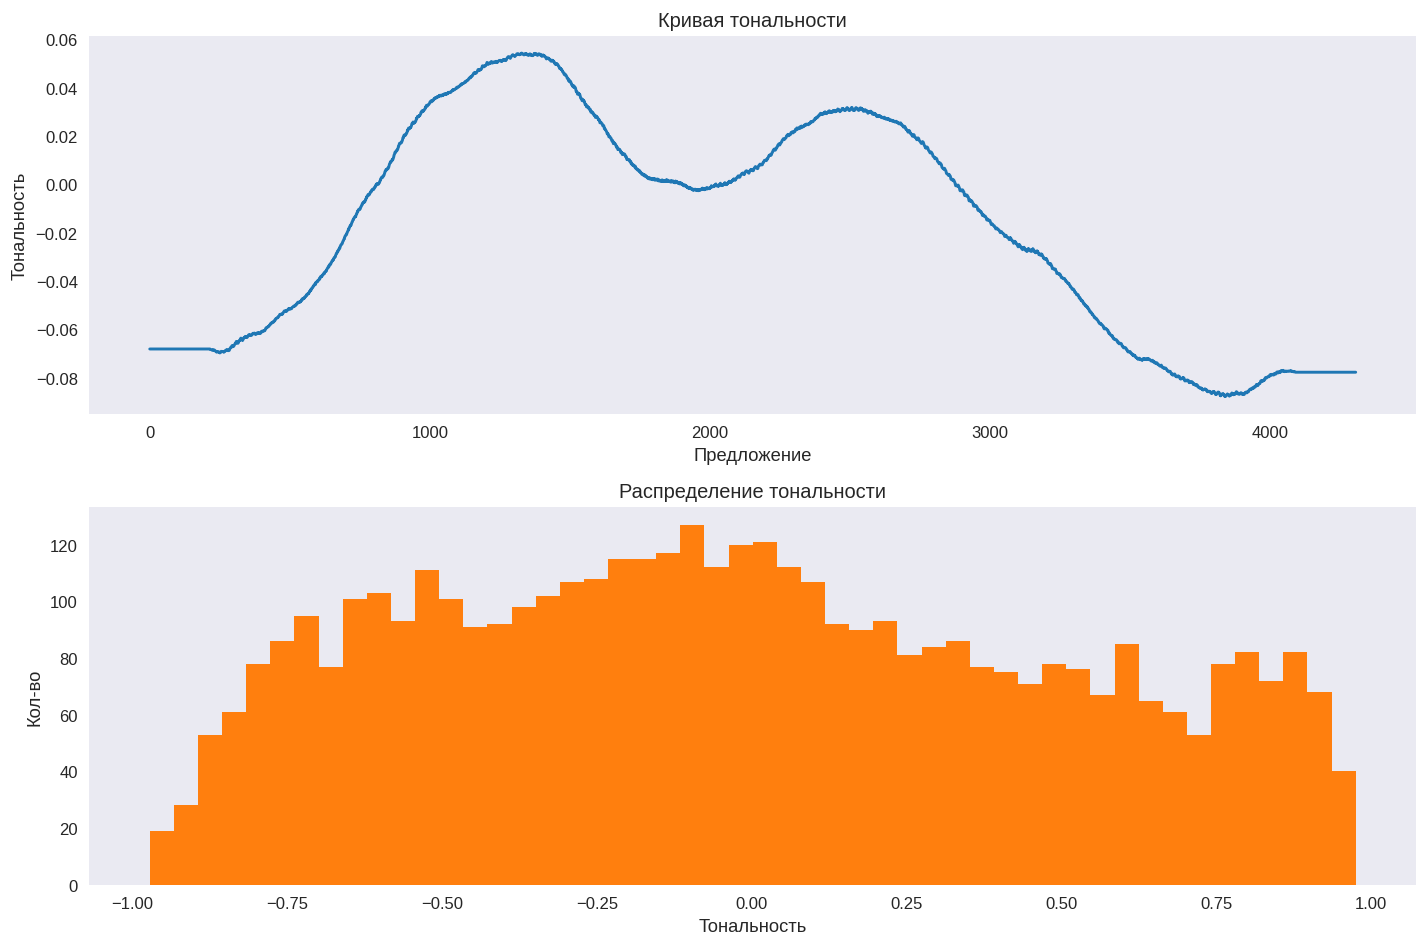

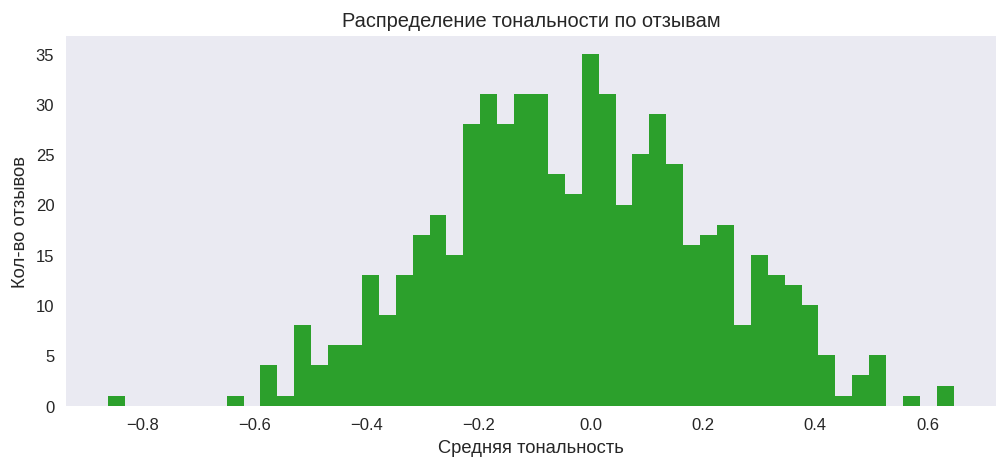

In [17]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import re
import numpy as np
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from matplotlib import pyplot as plt
from scipy.signal import savgol_filter
from tqdm.auto import tqdm

model_checkpoint = 'cointegrated/rubert-tiny-sentiment-balanced'
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)
model = AutoModelForSequenceClassification.from_pretrained(model_checkpoint)
if torch.cuda.is_available():
    model.cuda()

def estimate_sentiment(messages, batch_size=64, max_length=128):
    out = []
    for i in tqdm(range(0, len(messages), batch_size), desc="sentiment"):
        batch = messages[i:i + batch_size]
        with torch.no_grad():
            inputs = tokenizer(batch, return_tensors='pt', truncation=True, padding=True, max_length=max_length)
            inputs.pop('token_type_ids', None)
            inputs = inputs.to(model.device)
            proba = torch.sigmoid(model(**inputs).logits).cpu().numpy()
            scores = proba.dot([-1, 0, 1])
            # не выкидываем пустые строки, чтобы длина совпадала с borders
            for s, score in zip(batch, scores):
                out.append(score if s.strip() else 0.0)
    return np.array(out)

sentiments = estimate_sentiment(sentences)

def ensemble_filter(data, n_filters=20, polyorder=0, **kw):
    filt, n_used = 0, 0
    start, stop = len(data) // 10, len(data) // 4
    step = max((stop - start) // n_filters, 1)
    for w in range(start, stop, step):
        if w > len(data):
            continue
        if w % 2 == 0:
            w += 1
        filt += savgol_filter(data, window_length=w, polyorder=polyorder, **kw)
        n_used += 1
    return filt / max(n_used, 1)

filtered = ensemble_filter(sentiments)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), dpi=120)
axes[0].plot(filtered, color='tab:blue')
axes[0].set(xlabel='Предложение', ylabel='Тональность', title='Кривая тональности')
axes[0].grid()
axes[1].hist(sentiments, bins=50, color='tab:orange')
axes[1].set(xlabel='Тональность', ylabel='Кол-во', title='Распределение тональности')
axes[1].grid()
plt.tight_layout()
plt.show()

borders = np.cumsum([0] + n_sent_per_review)
# идём по длине n_sent_per_review, чтобы не поймать IndexError на df
review_scores = np.array([
    sentiments[borders[i]:borders[i+1]].mean() if n_sent_per_review[i] > 0 else 0.0
    for i in range(len(n_sent_per_review))
])

plt.figure(figsize=(10, 4), dpi=120)
plt.hist(review_scores, bins=50, color='tab:green')
plt.xlabel('Средняя тональность')
plt.ylabel('Кол-во отзывов')
plt.title('Распределение тональности по отзывам')
plt.grid()
plt.show()



отзывов: 10000


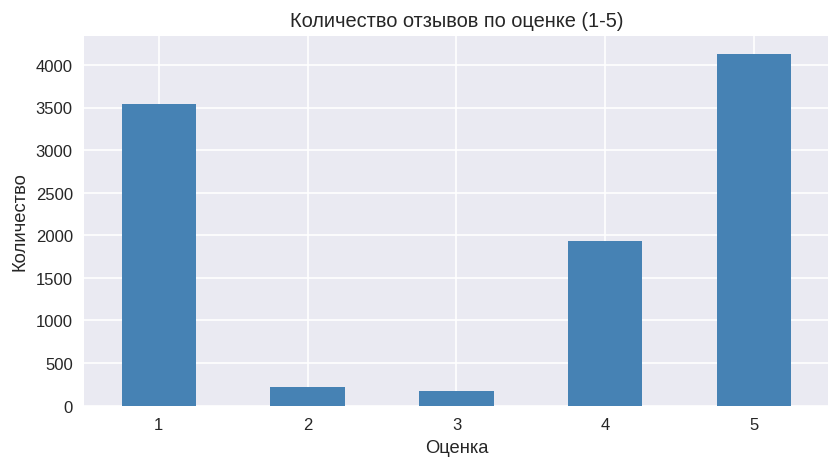

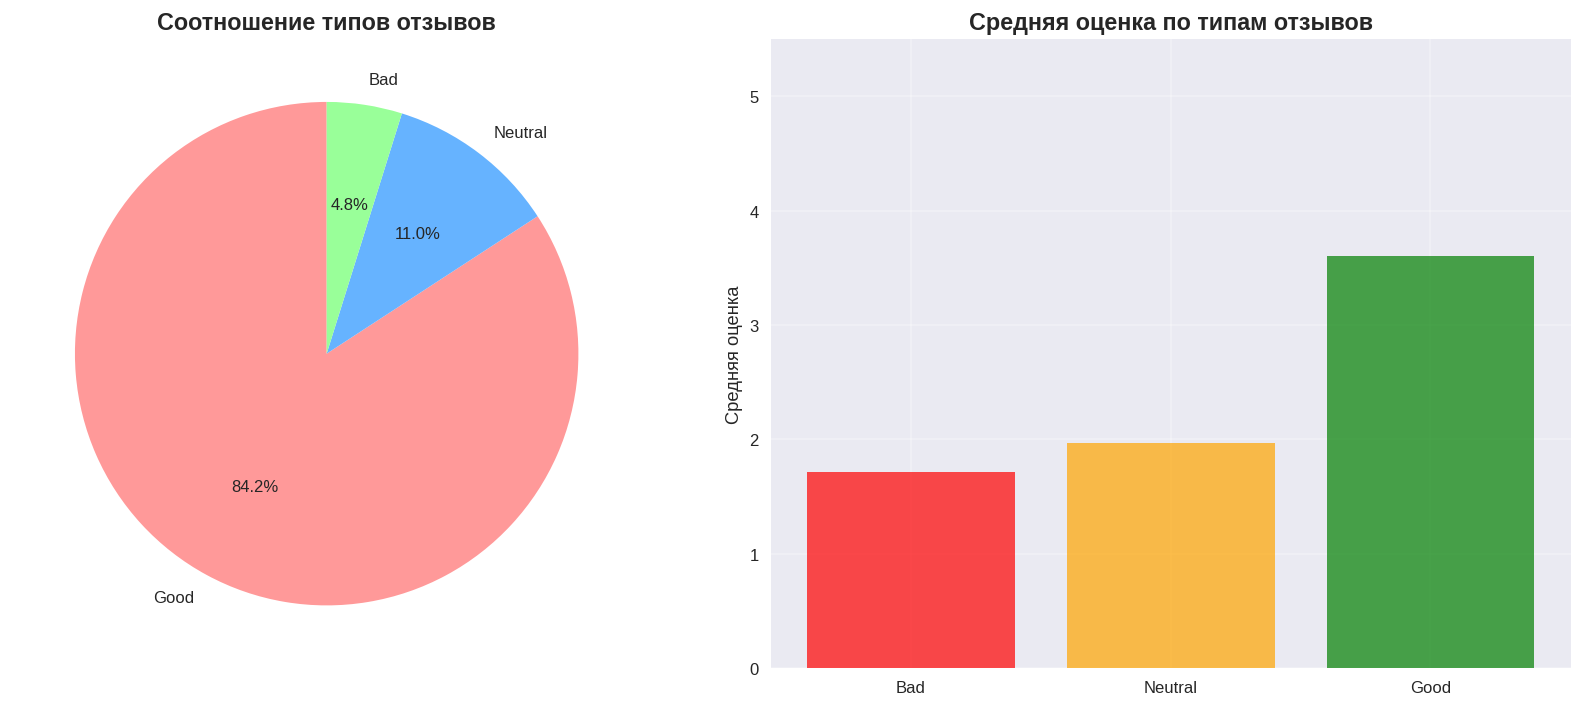

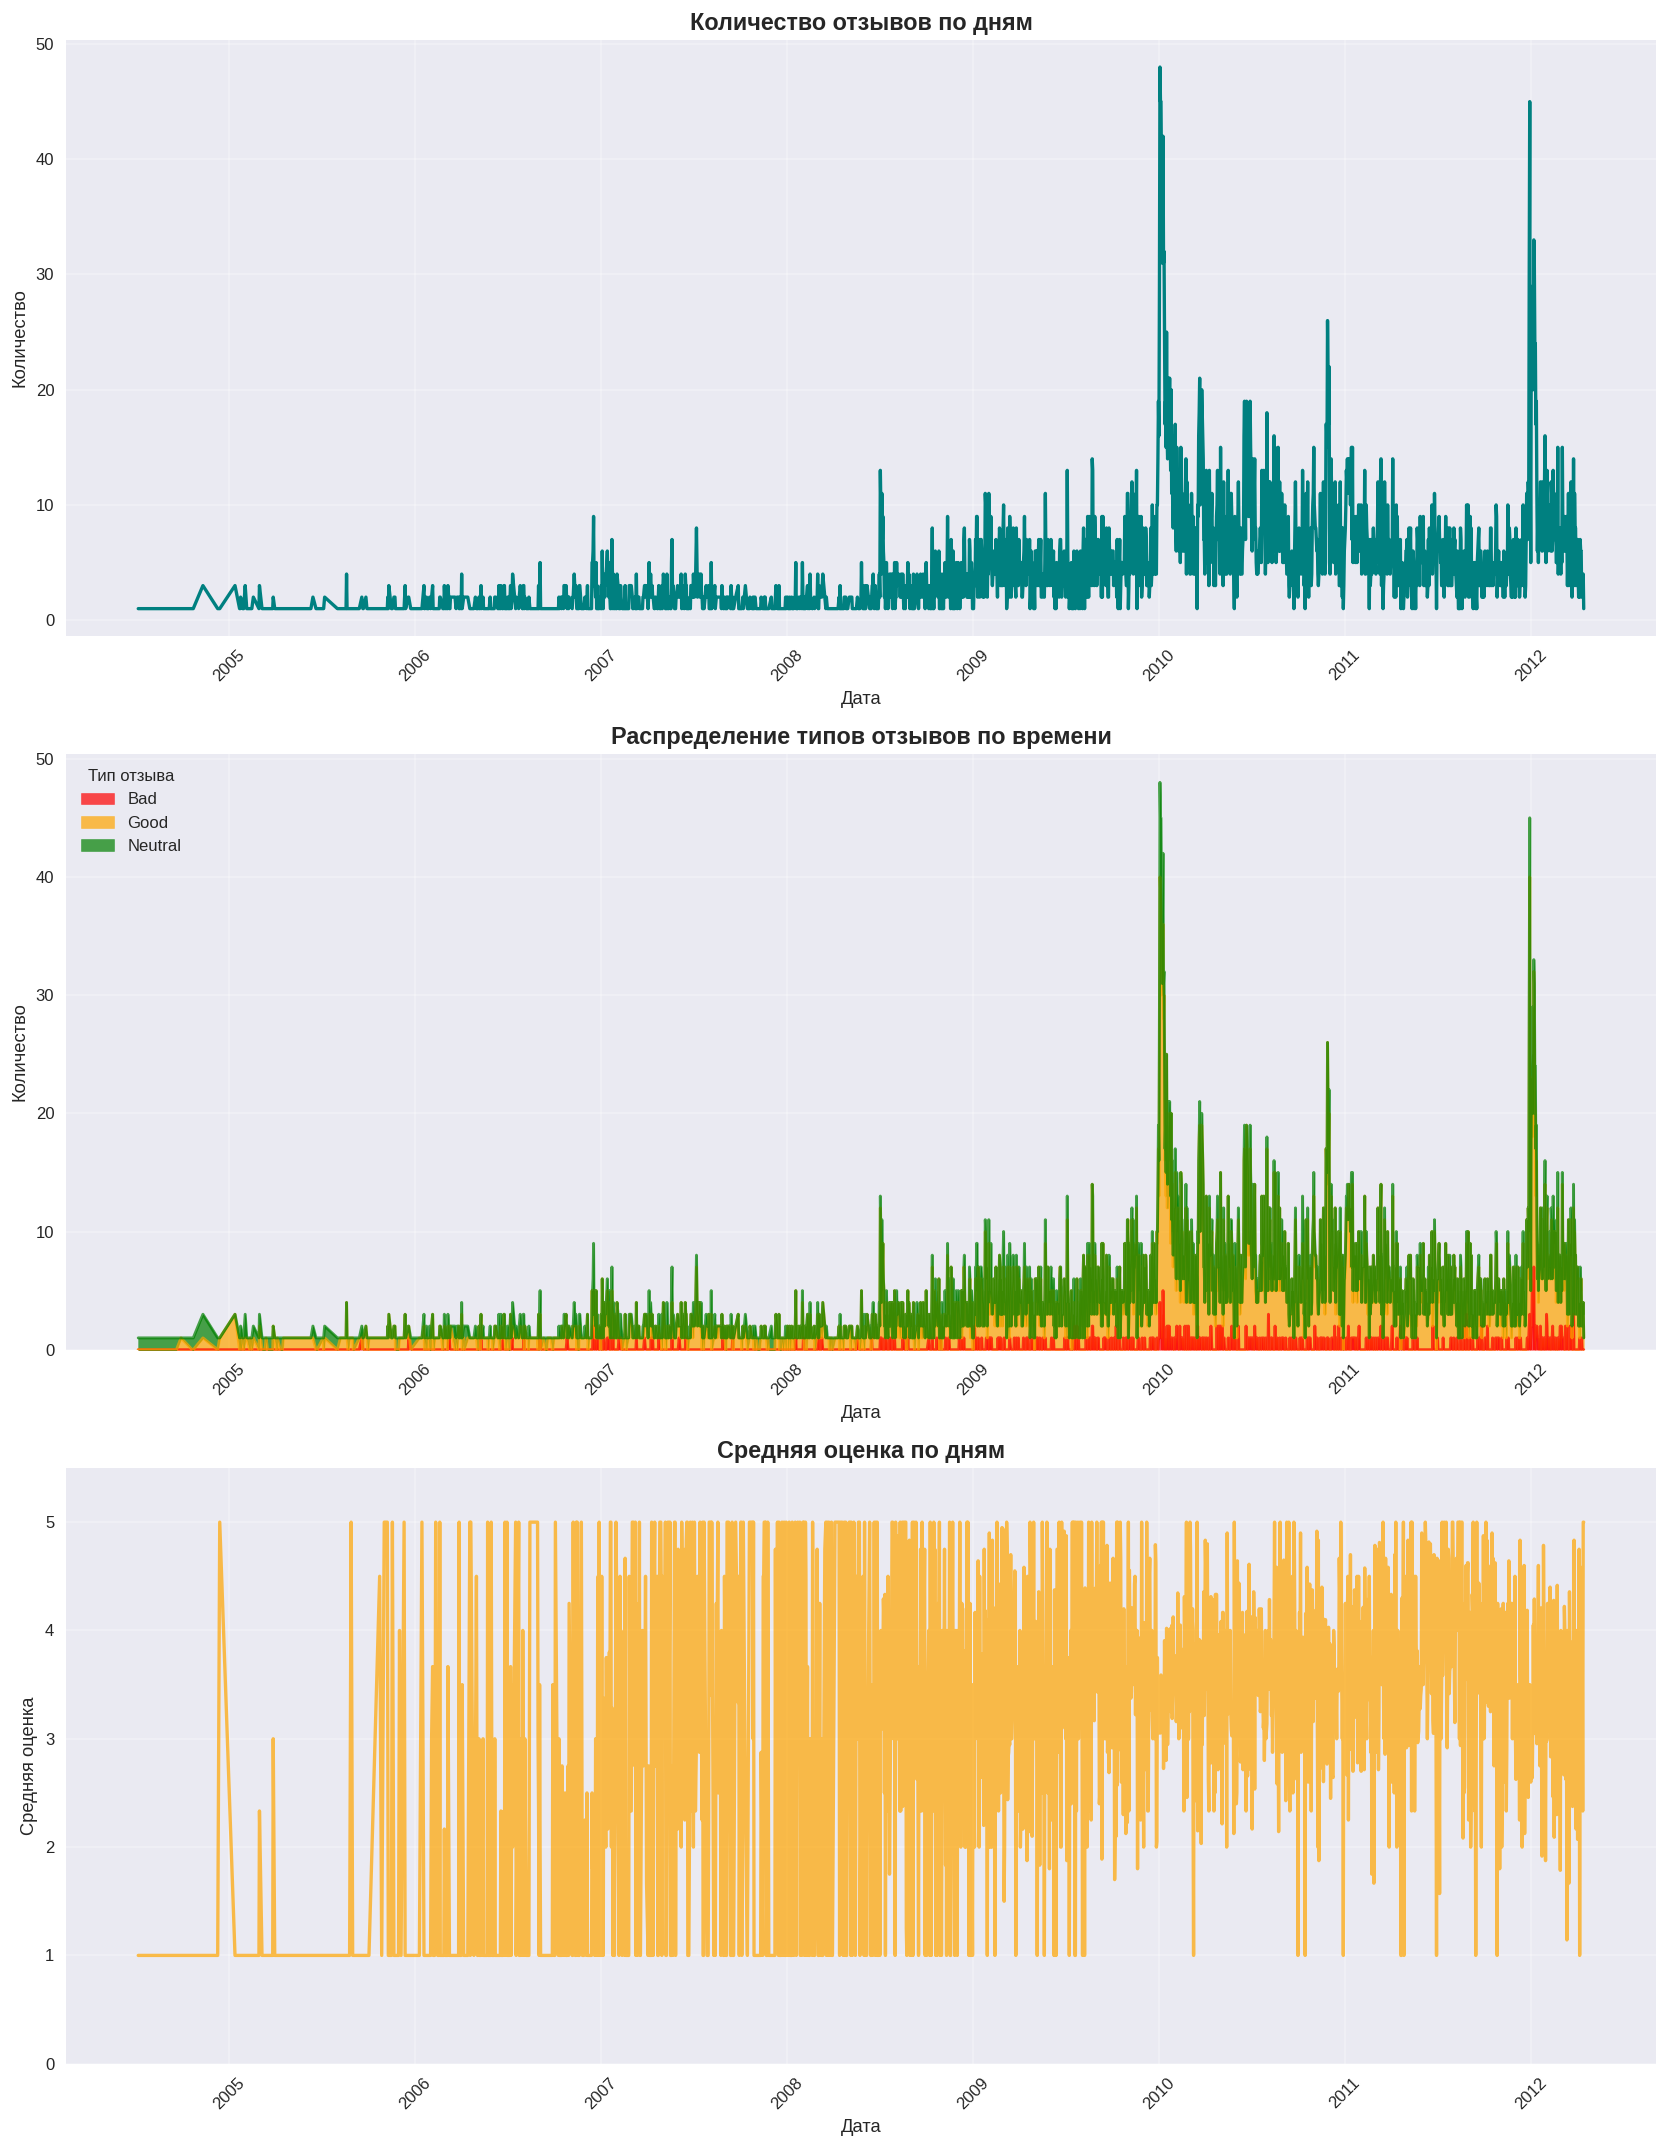

СТАТИСТИЧЕСКАЯ СВОДКА:
Всего отзывов: 10000
Период данных: от 2004-07-07 до 2012-04-14
Дней с отзывами: 2027

Распределение по типам:
label_text
Good       8419
Neutral    1098
Bad         483
Name: count, dtype: int64

Средняя оценка (1-5): 3.33
Медианная оценка (1-5): 4.50
Самый активный день недели: Sunday


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random
from datetime import datetime, timedelta
from datasets import load_dataset

plt.style.use('seaborn-v0_8')

ds = load_dataset("blinoff/kinopoisk", split="train[:10000]")
df = ds.to_pandas()
print(f"отзывов: {len(df)}")

df = df.rename(columns={'content': 'text', 'grade3': 'label_text'})
df['label'] = df['label_text'].map({'Bad': 0, 'Neutral': 1, 'Good': 2})

# grade10 приходит строкой, поэтому сначала в числа
df['grade10'] = pd.to_numeric(df['grade10'], errors='coerce')
df['rating'] = (df['grade10'] / 2).fillna(df['grade10'].median() / 2).clip(1, 5)

df = df.dropna(subset=['text', 'label_text']).reset_index(drop=True)

# в date нет времени, все часы будут 0, поэтому hour нигде не используется
df['data'] = pd.to_datetime(df['date'], errors='coerce')
if df['data'].isna().any():
    start_date = datetime(2004, 7, 1)
    end_date = datetime(2012, 11, 30)
    days_in_range = (end_date - start_date).days
    mask = df['data'].isna()
    df.loc[mask, 'data'] = [start_date + timedelta(days=random.randint(0, days_in_range))
                            for _ in range(mask.sum())]

df['date'] = df['data'].dt.date
df['month'] = df['data'].dt.month
df['day_of_week'] = df['data'].dt.day_name()
df['day_of_week_num'] = df['data'].dt.dayofweek

plt.figure(figsize=(8, 4), dpi=120)
ax = df['rating'].round().astype(int).value_counts().sort_index().plot(kind='bar', color='steelblue')
ax.set_title('Количество отзывов по оценке (1-5)')
ax.set_xlabel('Оценка')
ax.set_ylabel('Количество')
plt.xticks(rotation=0)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=120)
sentiment_counts = df['label_text'].value_counts()
colors = ['#ff9999', '#66b3ff', '#99ff99']
axes[0].pie(sentiment_counts.values, labels=sentiment_counts.index, autopct='%1.1f%%',
            colors=colors, startangle=90)
axes[0].set_title('Соотношение типов отзывов', fontsize=14, fontweight='bold')

rating_by_sentiment = df.groupby('label_text')['rating'].mean().reindex(['Bad', 'Neutral', 'Good'])
axes[1].bar(rating_by_sentiment.index, rating_by_sentiment.values,
            color=['red', 'orange', 'green'], alpha=0.7)
axes[1].set_title('Средняя оценка по типам отзывов', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Средняя оценка')
axes[1].set_ylim(0, 5.5)
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 1, figsize=(14, 18), dpi=120)

daily_reviews = df.groupby('date').size()
axes[0].plot(daily_reviews.index, daily_reviews.values, linewidth=2, color='teal')
axes[0].set_title('Количество отзывов по дням', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Дата')
axes[0].set_ylabel('Количество')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, alpha=0.3)

sentiment_over_time = df.groupby(['date', 'label_text']).size().unstack(fill_value=0)
sentiment_over_time.plot(kind='area', stacked=True, alpha=0.7, ax=axes[1],
                         color=['red', 'orange', 'green'])
axes[1].set_title('Распределение типов отзывов по времени', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Дата')
axes[1].set_ylabel('Количество')
axes[1].legend(title='Тип отзыва', loc='upper left')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(True, alpha=0.3)

rating_over_time = df.groupby('date')['rating'].mean()
axes[2].plot(rating_over_time.index, rating_over_time.values, linewidth=2, color='orange', alpha=0.7)
axes[2].set_title('Средняя оценка по дням', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Дата')
axes[2].set_ylabel('Средняя оценка')
axes[2].set_ylim(0, 5.5)
axes[2].tick_params(axis='x', rotation=45)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("=" * 50)
print("СТАТИСТИЧЕСКАЯ СВОДКА:")
print("=" * 50)
print(f"Всего отзывов: {len(df)}")
print(f"Период данных: от {df['data'].min().strftime('%Y-%m-%d')} до {df['data'].max().strftime('%Y-%m-%d')}")
print(f"Дней с отзывами: {df['date'].nunique()}")
print("\nРаспределение по типам:")
print(df['label_text'].value_counts())
print(f"\nСредняя оценка (1-5): {df['rating'].mean():.2f}")
print(f"Медианная оценка (1-5): {df['rating'].median():.2f}")
print(f"Самый активный день недели: {df['day_of_week'].mode().iloc[0]}")